# When should a fitness app ask for a goal?
**SYNTHETIC PORTFOLIO CASE STUDY | Aviv Emanuel**

A hypothetical growth experiment comparing the same optional weekly goal prompt during onboarding or after the first completed workout. The decision is whether to move the prompt. Every record is generated. All subsequent estimates refer to simulations.

This notebook runs offline using local code and files. Rates, sample size, thresholds and seed were specified in `protocol.json` before the first simulation. Run All from this folder in a Python kernel with the dependencies in the README. The cells overwrite only reproducible files under `outputs/`.

No production data are used.

In [1]:
from pathlib import Path
import json
import math
from statistics import NormalDist
from analysis import load_protocol, run, generate_accounts, summarize, METRICS
from render import render, result_line, percent_text
from validate import validate
protocol = load_protocol()
print(json.dumps(protocol, indent=2))

{
  "label": "SYNTHETIC PORTFOLIO EXERCISE",
  "version": "1.0",
  "frozen_before_first_simulation": true,
  "seed": 20261125,
  "accounts_per_arm": 20000,
  "allocation": "Complete randomization, fixed equal allocation, shuffled account IDs before onboarding",
  "primary": "Any completed workout in elapsed days 22-28 after assignment, inclusive",
  "diagnostic": "First completed workout by elapsed day 7, inclusive",
  "paid_guardrail": "Any first paid conversion by elapsed day 28",
  "error_guardrail": "Any logged onboarding error in elapsed days 0-7",
  "retention_minimum_worthwhile_lift_pp": 1.5,
  "paid_noninferiority_margin_pp": -1.0,
  "error_noninferiority_margin_pp": 0.5,
  "confidence_level": 0.95,
  "ci_method": "Newcombe difference of independent Wilson score intervals, uncorrected",
  "decision_order": [
    "If retention upper CI < 0, retain current timing due to retention harm",
    "If paid upper CI < -1.0pp or error lower CI > 0.5pp, retain current timing due to guardra

## Estimand and stopping rule

Randomize 40,000 new accounts before onboarding with fixed equal allocation. The intention-to-treat estimand is the deferred-minus-onboarding difference among all assigned accounts. Everyone has 28 days of follow-up. Prompt viewers and workout completers are post-assignment subsets and do not define the primary denominator.

Primary = any workout during days 22-28. Diagnostic = first workout by day 7. Guardrails = paid conversion through day 28 and onboarding errors through day 7.

Rollout requires a retention point estimate of at least +1.50 pp, a retention 95% lower bound above zero, a paid lower bound above -1.00 pp and an error upper bound below +0.50 pp. Clear primary or guardrail harm overrides activation improvements. All other outcomes retain current timing pending more evidence. One fixed-horizon readout is used.

In [2]:
p0 = .60*.36 + (1-.60)*.08*.25
p1 = p0 + .015
n = protocol['accounts_per_arm']
se = math.sqrt(p0*(1-p0)/n + p1*(1-p1)/n)
z = NormalDist().inv_cdf(.975)
power = 1-NormalDist().cdf(z-.015/se)+NormalDist().cdf(-z-.015/se)
print(f'Assumed control retention: {100*p0:.2f}%')
print(f'Approximate two-sided power for +1.50 pp: {100*power:.1f}%')
print('This is detection power, not the probability of passing the entire rollout rule.')

Assumed control retention: 22.40%
Approximate two-sided power for +1.50 pp: 94.5%
This is detection power, not the probability of passing the entire rollout rule.


## Generate once from the frozen specification

The seed is 20261125. There is no seed search. Re-execution reproduces the same files. The main scenario assumes increased early completion and lower subsequent return among early completers. Null and aligned-benefit cases test sensitivity to those assumptions. They reuse common random draws and are alternative worlds, not independent experiments.

First-workout timing and later return are linked. Payment and error outcomes are deliberately simplified independent draws. See `data_dictionary.md` and the protocol for details.

In [3]:
results = run()
main = results['scenarios']['main_conflict']
print('Protocol SHA-256:', results['protocol_sha256'])
print('Decision:', main['decision'])
for metric in main['metrics'].values():
    print(metric['label'])
    print(f"  Onboarding {metric['control_count']:,}/{metric['control_n']:,} ({percent_text(metric, 'control')})")
    print(f"  Deferred {metric['treatment_count']:,}/{metric['treatment_n']:,} ({percent_text(metric, 'treatment')})")
    print('  Difference [95% CI]:', result_line(metric))
print('Treatment prompt unseen:', n-main['prompt_seen']['after_workout'])

Protocol SHA-256: 32e581f485e9e86c70ae1153476ae7bb111b58867cadde7a42ca4a2a4a50e565
Decision: RETAIN_CURRENT_RETENTION_HARM
Week-four workout retention
  Onboarding 4,534/20,000 (22.67%)
  Deferred 3,978/20,000 (19.89%)
  Difference [95% CI]: -2.78 pp [-3.58, -1.98]
First workout by day 7
  Onboarding 12,004/20,000 (60.02%)
  Deferred 13,251/20,000 (66.26%)
  Difference [95% CI]: +6.24 pp [+5.29, +7.18]
Paid conversion by day 28
  Onboarding 1,208/20,000 (6.04%)
  Deferred 1,222/20,000 (6.11%)
  Difference [95% CI]: +0.07 pp [-0.40, +0.54]
Onboarding error by day 7
  Onboarding 316/20,000 (1.58%)
  Deferred 299/20,000 (1.50%)
  Difference [95% CI]: -0.09 pp [-0.33, +0.16]
Treatment prompt unseen: 6242


## Reconstruct metrics independently in SQL

Blank event days become SQL NULL. No exposure or completion filter is applied. The SQL result must agree with the Python event counts for every outcome.

In [4]:
import csv
import sqlite3
with open('outputs/synthetic_accounts.csv', newline='') as handle:
    records = list(csv.DictReader(handle))
columns = list(records[0])
numeric = set(columns)-{'account_id','scenario','arm'}
conn = sqlite3.connect(':memory:')
conn.execute('CREATE TABLE accounts ('+', '.join(c+(' INTEGER' if c in numeric else ' TEXT') for c in columns)+')')
values = [tuple(None if row[c]=='' else int(row[c]) if c in numeric else row[c] for c in columns) for row in records]
conn.executemany('INSERT INTO accounts VALUES ('+','.join('?' for _ in columns)+')',values)
query = Path('metrics.sql').read_text()
print(query)
for arm, assigned, *counts in conn.execute(query):
    prefix = 'control' if arm=='onboarding' else 'treatment'
    assert assigned == n
    for key, count in zip(METRICS, counts):
        assert count == main['metrics'][key][prefix+'_count']
    print(arm, assigned, dict(zip(METRICS, counts)))
conn.close()

-- SYNTHETIC portfolio exercise. All assigned accounts remain in denominators.
SELECT
    arm,
    COUNT(*) AS assigned_accounts,
    SUM(CASE WHEN week4_workout_day BETWEEN 22 AND 28 THEN 1 ELSE 0 END) AS retention_w4,
    SUM(CASE WHEN first_workout_day BETWEEN 0 AND 7 THEN 1 ELSE 0 END) AS first_workout_d7,
    SUM(CASE WHEN first_paid_day BETWEEN 0 AND 28 THEN 1 ELSE 0 END) AS paid_d28,
    SUM(CASE WHEN onboarding_error_day BETWEEN 0 AND 7 THEN 1 ELSE 0 END) AS error_d7
FROM accounts
GROUP BY arm;

after_workout 20000 {'retention_w4': 3978, 'first_workout_d7': 13251, 'paid_d28': 1222, 'error_d7': 299}
onboarding 20000 {'retention_w4': 4534, 'first_workout_d7': 12004, 'paid_d28': 1208, 'error_d7': 316}


## Confidence intervals and product judgment

For each binary outcome, compute a Wilson interval in each arm. Combine the two via Newcombe's independent-proportions construction to estimate the difference. The implementation is in `analysis.py`; the validation compares it with a separate normal approximation and checks a zero-event boundary.

These intervals quantify random variation within the chosen model. They provide no calibration to real users. The diagnostic is descriptive and cannot override the primary outcome.

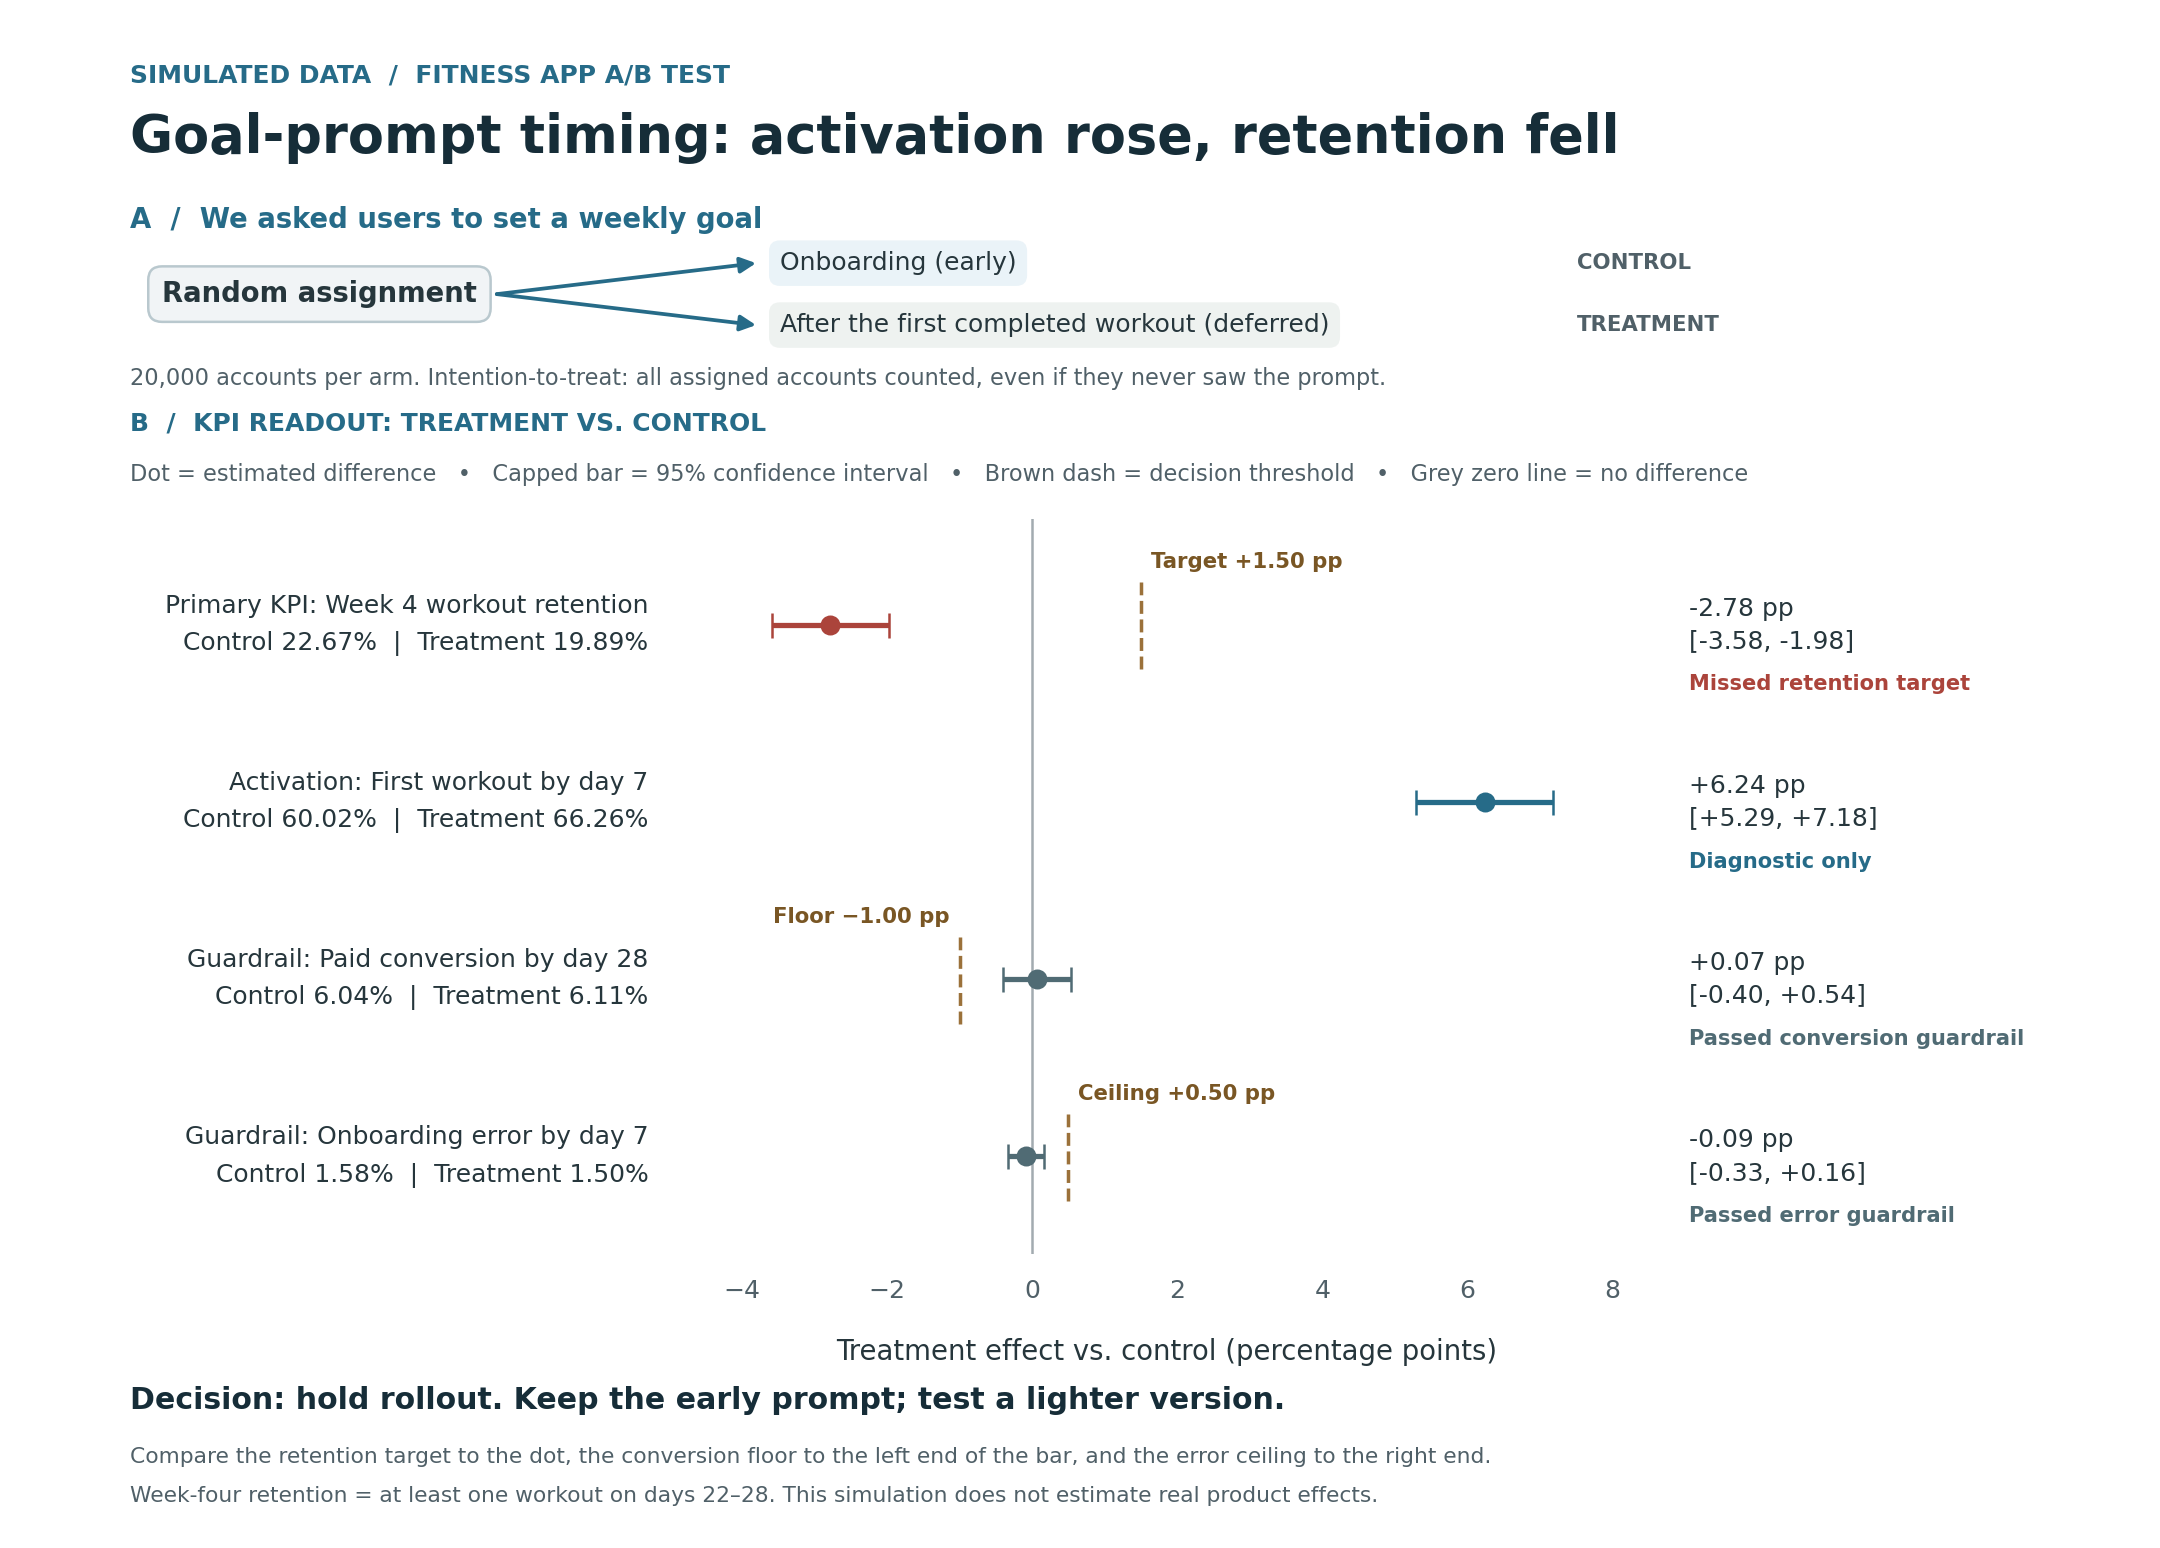

In [5]:
render()
from IPython.display import Image, display
display(Image(filename='outputs/results_chart.png'))

## Sensitivity and decision

The frozen decision rule is applied identically across all three scenarios. A lighter onboarding prompt is the next proposed product bet under the main result. Mechanism would need additional evidence. Inspecting paths can generate hypotheses, while an independently randomized follow-up tests the revised feature.

In [6]:
for scenario, item in results['scenarios'].items():
    print(scenario)
    print('  Retention:', result_line(item['metrics']['retention_w4']))
    print('  Decision:', item['decision'])
print(Path('outputs/decision_memo.md').read_text())

main_conflict
  Retention: -2.78 pp [-3.58, -1.98]
  Decision: RETAIN_CURRENT_RETENTION_HARM
null
  Retention: -0.09 pp [-0.91, +0.73]
  Decision: RETAIN_CURRENT_MORE_EVIDENCE
aligned_benefit
  Retention: +3.23 pp [+2.39, +4.07]
  Decision: SIMULATED_ROLLOUT
# When should a fitness app ask for a goal?

**SYNTHETIC PORTFOLIO EXERCISE | V1 | 25 November 2026**

## Decision

Retain the onboarding goal prompt in this simulated case. The first-workout gain accompanies a clear decline in the primary retention metric. Test a shorter onboarding prompt in a separate follow-up experiment.

## Product question and design

Would moving the same optional weekly goal prompt until after the first completed workout improve sustained use? Randomize new eligible accounts before onboarding, with 20,000 per arm and 28 complete days of follow-up. Keep wording, skip option, workouts, prices and reminders identical. Goal capture does not change workout selection.

## Frozen success criteria

Recommend rollou

## Validation and reproducibility

The core analysis uses only the Python standard library. `run_all.py` regenerates results and artifacts with outbound networking blocked. This validation checks deterministic reruns, persisted CSV counts, independent SQL results, unexposed-account inclusion, intervals, policy branches and memo/PDF consistency. Visual inspection separately confirmed the standalone figure and one-page PDF.

In [7]:
validation = validate()
assert validation['status']=='PASS'
print('All executed checks passed.')

{
  "status": "PASS",
  "checks": [
    "Fresh deterministic rerun matches numeric outputs and account CSV byte for byte",
    "CSV-derived estimates agree with JSON; 40,000 unique accounts and 20,000 per arm",
    "Independent SQLite metric query matches all eight event counts and denominators",
    "All 6,242 unexposed treatment accounts remain included",
    "Interval cross-check within 0.02 pp; zero-event boundary retains uncertainty",
    "Conflicting, null, aligned-benefit, guardrail-harm and uncertain-guardrail decisions checked",
    "Editable memo contains every calculated difference and interval",
    "One-page PDF contains every calculated difference, interval and synthetic label"
  ],
  "decisions": {
    "main_conflict": "RETAIN_CURRENT_RETENTION_HARM",
    "null": "RETAIN_CURRENT_MORE_EVIDENCE",
    "aligned_benefit": "SIMULATED_ROLLOUT"
  },
  "protocol_sha256": "32e581f485e9e86c70ae1153476ae7bb111b58867cadde7a42ca4a2a4a50e565"
}
All executed checks passed.


## Public context

Aviv's [retention case](https://www.avivemanuel.com/post/loyal-users-early-behaviors) describes a 23% improvement in prediction and stakeholder action. The present synthetic case extends the portfolio toward causal experiment design and a product decision. It establishes no additional real retention impact.

This source provides context only and was checked on November 25, 2026.